# Explainable AI for Diabetic Retinopathy Screening in Rural India
**End-term project** - APTOS 2019 Blindness Detection (Kaggle), 3,662 colour fundus images, 5 ICDR grades.

Pipeline: data audit -> EDA -> preprocessing -> MobileNetV2 transfer learning -> evaluation -> Grad-CAM explanations.

## 2. Data collection
Source: [APTOS 2019](https://www.kaggle.com/c/aptos2019-blindness-detection) (Aravind Eye Hospital, India). The labelled Kaggle train set (3,662 images) was split into train / validation / test CSVs.

In [2]:
import tensorflow as tf
from pathlib import Path

# Change this to the folder where you downloaded APTOS 2019.
DATASET_DIR = Path(r"C:\Users\shres\OneDrive\Desktop\diabetic\Diabetic\DataBase")

print("Dataset folder exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    print("\nFiles and folders:")

    for item in DATASET_DIR.iterdir():
        if item.is_dir():
            print(f"[FOLDER] {item.name}")
        else:
            print(f"[FILE]   {item.name}")

Dataset folder exists: True

Files and folders:
[FOLDER] cache_224
[FILE]   retinova.db
[FILE]   test.csv
[FOLDER] test_images
[FILE]   train_1.csv
[FOLDER] train_images
[FILE]   valid.csv
[FOLDER] val_images


In [3]:
import pandas as pd
files = {
    "Train": DATASET_DIR / "train_1.csv",
    "Validation": DATASET_DIR / "valid.csv",
    "Test": DATASET_DIR / "test.csv",
}

for name, path in files.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head())

    if "diagnosis" in df.columns:
        print("\nClass distribution:")
        print(df["diagnosis"].value_counts().sort_index())


=============== Train ===============
Shape: (2930, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  1ae8c165fd53          2
1  1b329a127307          1
2  1b32e1d775ea          4
3  1b3647865779          0
4  1b398c0494d1          0

Class distribution:
diagnosis
0    1434
1     300
2     808
3     154
4     234
Name: count, dtype: int64

=============== Validation ===============
Shape: (366, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0

Class distribution:
diagnosis
0    172
1     40
2    104
3     22
4     28
Name: count, dtype: int64

=============== Test ===============
Shape: (366, 2)
Columns: ['id_code', 'diagnosis']
        id_code  diagnosis
0  e4dcca36ceb4          0
1  e4e343eaae2a          2
2  e4f12411fd85          4
3  e50b0174690d          0
4  e5197d77ec68          0

Class distribution:
diagnosis
0 

In [4]:
# ===== Cell 5: Shared settings and plot style =====
# Purpose: one place for paths, grade names and a consistent colour per DR grade.
import json
import numpy as np
import matplotlib.pyplot as plt

train_df = pd.read_csv(DATASET_DIR / "train_1.csv")
valid_df = pd.read_csv(DATASET_DIR / "valid.csv")
test_df = pd.read_csv(DATASET_DIR / "test.csv")

IMAGE_DIRS = {"train": DATASET_DIR / "train_images",
              "valid": DATASET_DIR / "val_images",
              "test": DATASET_DIR / "test_images"}

grade_labels = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative DR"}
# fixed colour per grade (same colour = same grade in every figure)
GRADE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]

OUTPUT_DIR = Path("graphs"); OUTPUT_DIR.mkdir(exist_ok=True)
RESULTS_DIR = Path("../results"); RESULTS_DIR.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#898781", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10,
})

## 3. Data quality: missing values, duplicates, leakage, missing files

In [5]:
# ===== Cell 6: Data quality audit =====
# Purpose: make sure labels are complete, IDs are unique, splits do not overlap
# and every CSV row has an image on disk.
splits = {"train": train_df, "valid": valid_df, "test": test_df}
audit = []
for name, df in splits.items():
    files_on_disk = {p.stem for p in IMAGE_DIRS[name].glob("*.png")}
    audit.append({
        "split": name,
        "rows": len(df),
        "missing_values": int(df.isna().sum().sum()),
        "duplicate_ids": int(df["id_code"].duplicated().sum()),
        "invalid_labels": int((~df["diagnosis"].isin(range(5))).sum()),
        "missing_image_files": int((~df["id_code"].isin(files_on_disk)).sum()),
    })
audit_df = pd.DataFrame(audit)
print(audit_df.to_string(index=False))

# leakage check: an image must appear in only one split
ids = {k: set(v["id_code"]) for k, v in splits.items()}
print("\nTrain/Valid overlap:", len(ids["train"] & ids["valid"]))
print("Train/Test overlap :", len(ids["train"] & ids["test"]))
print("Valid/Test overlap :", len(ids["valid"] & ids["test"]))

split  rows  missing_values  duplicate_ids  invalid_labels  missing_image_files
train  2930               0              0               0                    0
valid   366               0              0               0                    0
 test   366               0              0               0                    0

Train/Valid overlap: 0
Train/Test overlap : 0
Valid/Test overlap : 0


## 4. Exploratory data analysis
### 4.1 Label distribution and split balance

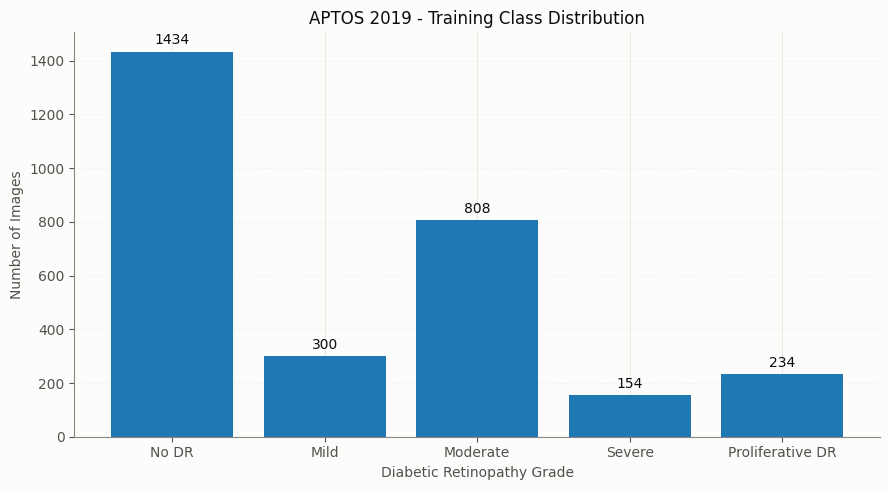

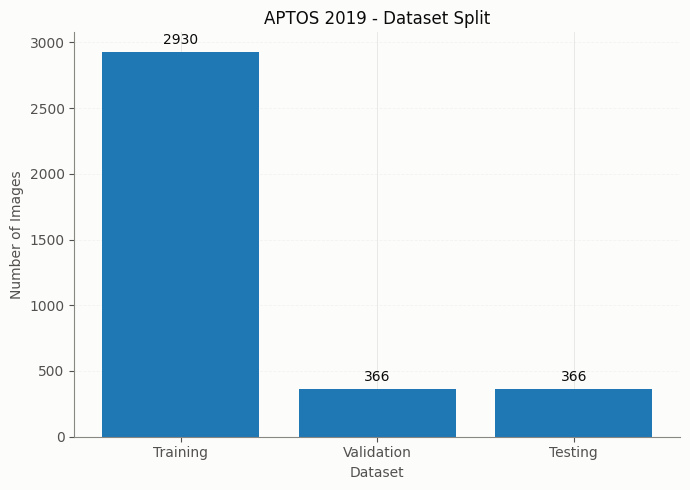

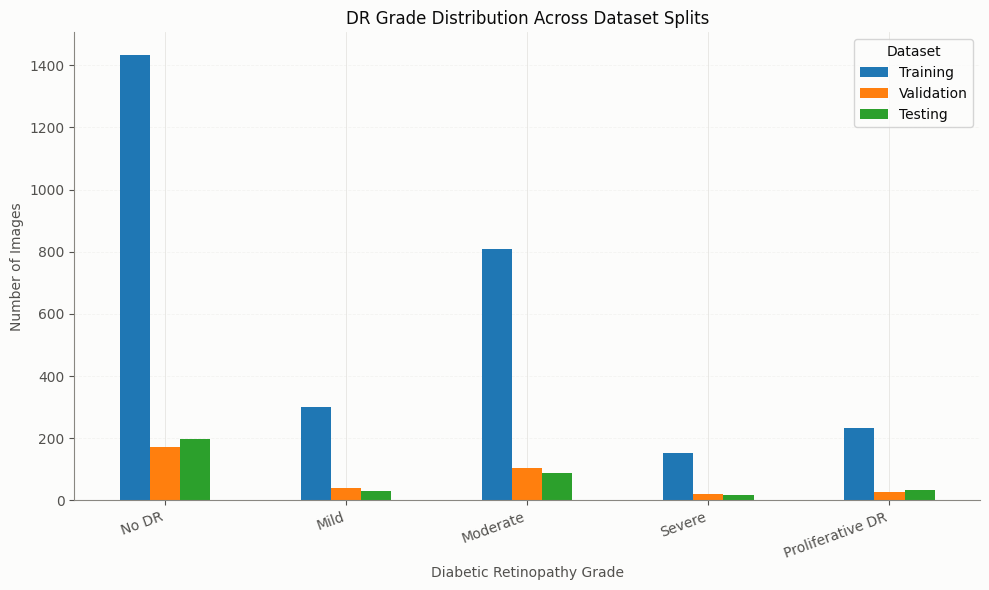

All graphs generated successfully!
Saved in: C:\Users\shres\OneDrive\Desktop\diabetic\Diabetic\graphs


In [6]:
import matplotlib.pyplot as plt

# Load CSV files
train_df = pd.read_csv(DATASET_DIR / "train_1.csv")
valid_df = pd.read_csv(DATASET_DIR / "valid.csv")
test_df = pd.read_csv(DATASET_DIR / "test.csv")

# DR grade labels
grade_labels = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

# Create output directory for graphs
OUTPUT_DIR = Path("graphs")
OUTPUT_DIR.mkdir(exist_ok=True)


# --------------------------------------------------
# GRAPH 1: Class distribution in training dataset
# --------------------------------------------------

train_counts = (
    train_df["diagnosis"]
    .value_counts()
    .reindex(range(5), fill_value=0)
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    [grade_labels[i] for i in range(5)],
    train_counts.values
)

plt.title("APTOS 2019 - Training Class Distribution")
plt.xlabel("Diabetic Retinopathy Grade")
plt.ylabel("Number of Images")
plt.bar_label(bars, padding=3)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=300)
plt.show()


# --------------------------------------------------
# GRAPH 2: Dataset split
# --------------------------------------------------

split_names = ["Training", "Validation", "Testing"]
split_counts = [
    len(train_df),
    len(valid_df),
    len(test_df)
]

plt.figure(figsize=(7, 5))

bars = plt.bar(split_names, split_counts)

plt.title("APTOS 2019 - Dataset Split")
plt.xlabel("Dataset")
plt.ylabel("Number of Images")
plt.bar_label(bars, padding=3)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "dataset_split.png", dpi=300)
plt.show()


# --------------------------------------------------
# GRAPH 3: Compare class distributions
# --------------------------------------------------

class_comparison = pd.DataFrame({
    "Training": train_df["diagnosis"].value_counts(),
    "Validation": valid_df["diagnosis"].value_counts(),
    "Testing": test_df["diagnosis"].value_counts()
}).reindex(range(5), fill_value=0)

class_comparison.index = [
    grade_labels[i] for i in class_comparison.index
]

ax = class_comparison.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title("DR Grade Distribution Across Dataset Splits")
ax.set_xlabel("Diabetic Retinopathy Grade")
ax.set_ylabel("Number of Images")
ax.legend(title="Dataset")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "class_comparison.png", dpi=300)
plt.show()


print("All graphs generated successfully!")
print("Saved in:", OUTPUT_DIR.resolve())

In [7]:
# ===== Cell 8: Class imbalance numbers =====
# Purpose: quantify the imbalance that the model has to cope with.
counts = train_df["diagnosis"].value_counts().sort_index()
imb = pd.DataFrame({"grade": [grade_labels[i] for i in counts.index],
                    "images": counts.values,
                    "percent": (100 * counts / counts.sum()).round(1).values})
print(imb.to_string(index=False))
print(f"\nImbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f} : 1")
referable = (train_df["diagnosis"] >= 2).mean() * 100
print(f"Referable DR (grade >= 2) in training set: {referable:.1f}%")  

           grade  images  percent
           No DR    1434     48.9
            Mild     300     10.2
        Moderate     808     27.6
          Severe     154      5.3
Proliferative DR     234      8.0

Imbalance ratio (largest / smallest class): 9.3 : 1
Referable DR (grade >= 2) in training set: 40.8%


### 4.2 Sample fundus images per grade

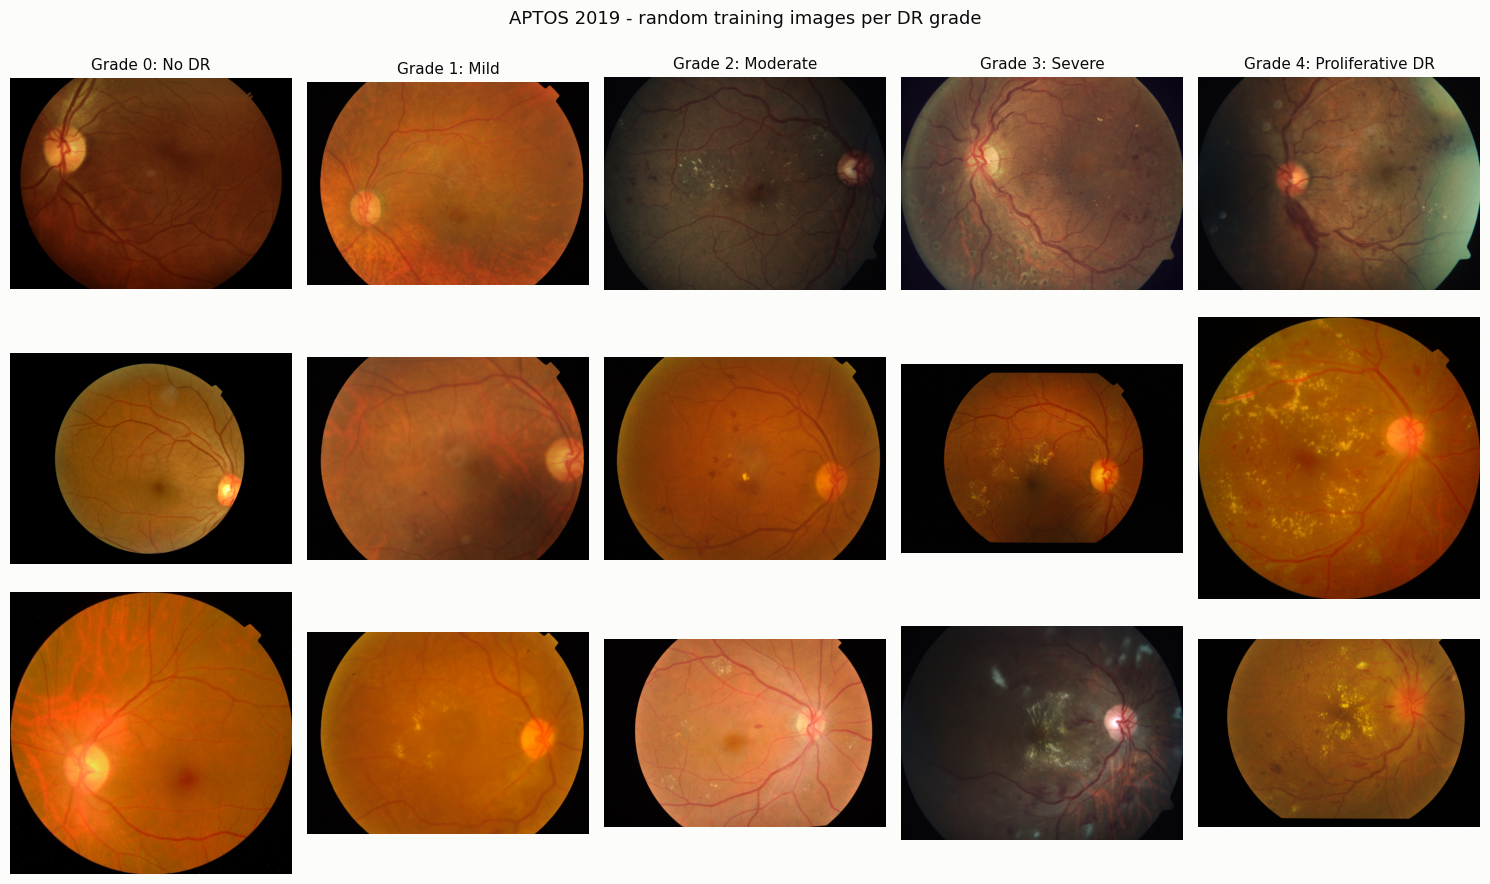

In [8]:
# ===== Cell 9: Sample images per grade =====
# Purpose: look at the raw data the model sees.
import cv2

def read_rgb(path):
    return cv2.cvtColor(cv2.imread(str(path)), cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for g in range(5):
    ids_g = train_df[train_df["diagnosis"] == g]["id_code"].sample(3, random_state=42)
    for r, img_id in enumerate(ids_g):
        ax = axes[r, g]
        ax.imshow(read_rgb(IMAGE_DIRS["train"] / f"{img_id}.png"))
        ax.axis("off")
        if r == 0:
            ax.set_title(f"Grade {g}: {grade_labels[g]}", fontsize=11)
plt.suptitle("APTOS 2019 - random training images per DR grade", fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "sample_images.png", dpi=150)
plt.show()